In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path("bao_server")
pg_path = root / "csvs" / "pg_only_full_run.csv"
bao_path = root / "csvs" / "bao_5000_run.csv"
outdir = root / "plots" / "bao_vs_pg_notebook"
outdir.mkdir(parents=True, exist_ok=True)

pg_raw = pd.read_csv(pg_path)
bao_raw = pd.read_csv(bao_path)

# The Bao log contains a PostgreSQL warm-up phase and a Bao-active phase.
bao_active = bao_raw.loc[bao_raw["run_type"].eq("Bao-active")].copy()

# Compare the same query files in both runs; query_id is a run-local order.
pg = pg_raw.copy()
bao = bao_active.copy()
matched_files = set(pg["query_file"]) & set(bao["query_file"])
pg = pg.loc[pg["query_file"].isin(matched_files)].copy()
bao = bao.loc[bao["query_file"].isin(matched_files)].copy()
if pg["query_file"].duplicated().any() or bao["query_file"].duplicated().any():
    raise ValueError("Each query_file must occur at most once in each run.")
if pg.empty:
    raise ValueError("No matching Bao-active queries were found in the PostgreSQL log.")

print(f"PostgreSQL rows: {len(pg_raw)}")
print(f"Bao rows: {len(bao_raw)} ({len(bao_active)} Bao-active)")
print(f"Matched Bao-active queries: {len(pg)}")

PostgreSQL rows: 8829
Bao rows: 8829 (7829 Bao-active)
Matched Bao-active queries: 7829


In [8]:
def prepare_run(df, label):
    result = df.sort_values("query_id").reset_index(drop=True).copy()
    result["run_type"] = label
    result["duration_sec"] = result["duration_ms"] / 1000.0
    result["query_index"] = np.arange(1, len(result) + 1)
    result["cumulative_count"] = result["query_index"]
    result["elapsed_since_t0_sec"] = result["duration_sec"].cumsum()
    result["gap_sec"] = np.nan
    return result

pg = prepare_run(pg, "PostgreSQL")
bao = prepare_run(bao, "Bao")

# Use the same query set for paired latency comparisons.
paired = pg[["query_file", "duration_ms"]].merge(
    bao[["query_file", "duration_ms"]],
    on="query_file",
    suffixes=("_pg", "_bao"),
    validate="one_to_one",
)
positive = paired[(paired["duration_ms_pg"] > 0) & (paired["duration_ms_bao"] > 0)].copy()
positive["speedup"] = positive["duration_ms_pg"] / positive["duration_ms_bao"]
positive["log2_speedup"] = np.log2(positive["speedup"])

percentiles = pd.DataFrame({
    "PostgreSQL (ms)": pg["duration_ms"].quantile(np.arange(1, 101) / 100).to_numpy(),
    "Bao (ms)": bao["duration_ms"].quantile(np.arange(1, 101) / 100).to_numpy(),
}, index=[f"p{i}" for i in range(1, 101)])

bao_faster = int((positive["speedup"] > 1).sum())
pg_faster = int((positive["speedup"] < 1).sum())
tied = int((positive["speedup"] == 1).sum())
summary_lines = [
    "=" * 70,
    "SUMMARY",
    "=" * 70,
    "",
    "Comparison basis: Bao-active queries matched to PostgreSQL by query_file.",
    "The input CSVs contain durations only; wall-clock gaps and crossover timing",
    "cannot be calculated without t_start/t_end timestamps.",
]
for label, frame in [("PostgreSQL", pg), ("Bao", bao)]:
    total = frame["duration_sec"].sum()
    summary_lines.extend([
        f"\\n{label}:",
        f"  queries completed    : {len(frame)}",
        f"  total query time      : {total:,.1f} sec ({total / 3600:.2f} hr)",
        f"  mean duration         : {frame['duration_sec'].mean():.3f} sec",
        f"  median (p50) duration : {frame['duration_sec'].median():.3f} sec",
        f"  p90 duration          : {frame['duration_sec'].quantile(.90):.3f} sec",
        f"  p95 duration          : {frame['duration_sec'].quantile(.95):.3f} sec",
        f"  p99 duration          : {frame['duration_sec'].quantile(.99):.3f} sec",
        f"  max duration          : {frame['duration_sec'].max():.3f} sec",
    ])
summary_lines.extend([
    "\\nMatched positive-duration queries:",
    f"  count                 : {len(positive)}",
    f"  Bao faster            : {bao_faster} ({bao_faster / len(positive):.1%})",
    f"  PostgreSQL faster     : {pg_faster} ({pg_faster / len(positive):.1%})",
    f"  equal                 : {tied} ({tied / len(positive):.1%})",
    "\\nWall-clock analysis:",
    "  inter-query gaps      : unavailable (timestamps absent)",
    "  cumulative crossover  : unavailable (timestamps absent)",
    "=" * 70,
])
summary = "\\n".join(summary_lines)
print(summary)
(outdir / "summary.txt").write_text(summary, encoding="utf-8")
percentiles.to_csv(outdir / "percentiles.csv")
print(f"Summary written to: {(outdir / 'summary.txt').resolve()}")
with pd.option_context("display.max_rows", 100):
    display(percentiles)

======================================================================\nSUMMARY\n======================================================================\n\nComparison basis: Bao-active queries matched to PostgreSQL by query_file.\nThe input CSVs contain durations only; wall-clock gaps and crossover timing\ncannot be calculated without t_start/t_end timestamps.\n\nPostgreSQL:\n  queries completed    : 7829\n  total query time      : 7,273.1 sec (2.02 hr)\n  mean duration         : 0.929 sec\n  median (p50) duration : 0.149 sec\n  p90 duration          : 2.529 sec\n  p95 duration          : 4.405 sec\n  p99 duration          : 7.344 sec\n  max duration          : 85.271 sec\n\nBao:\n  queries completed    : 7829\n  total query time      : 8,549.9 sec (2.37 hr)\n  mean duration         : 1.092 sec\n  median (p50) duration : 0.559 sec\n  p90 duration          : 2.219 sec\n  p95 duration          : 3.455 sec\n  p99 duration          : 7.648 sec\n  max duration          : 30.296 sec\n\nMatche

,PostgreSQL (ms),Bao (ms)
p1,8.351278,36.981335
p2,12.804146,56.499510
p3,15.753288,70.521307
p4,20.651455,86.953516
p5,23.311472,91.196299
p6,25.678167,93.740005
p7,31.612358,95.358992
p8,33.045149,97.300272
p9,34.219160,99.254141
p10,35.363293,102.083683


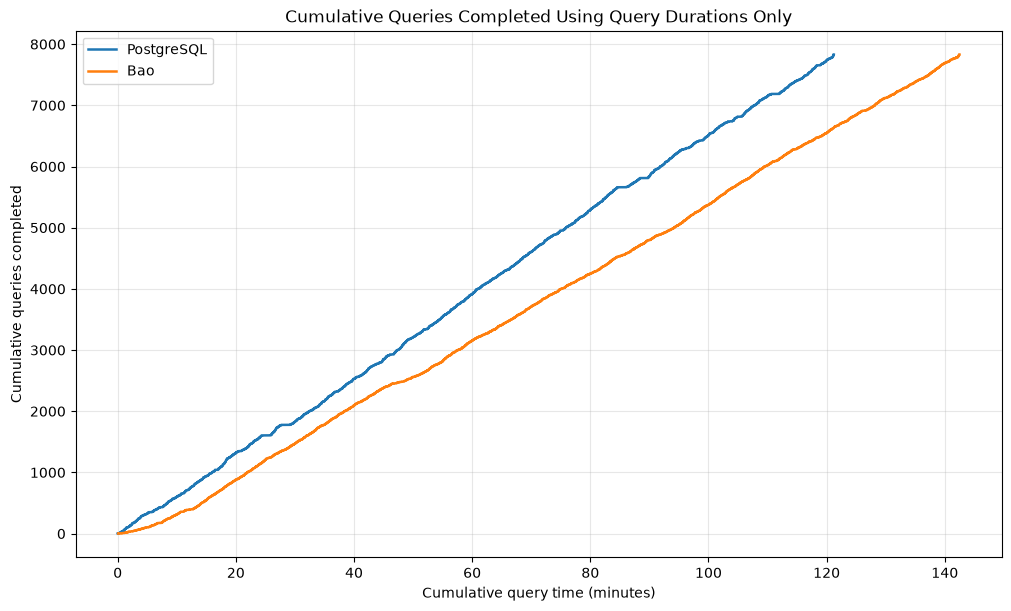

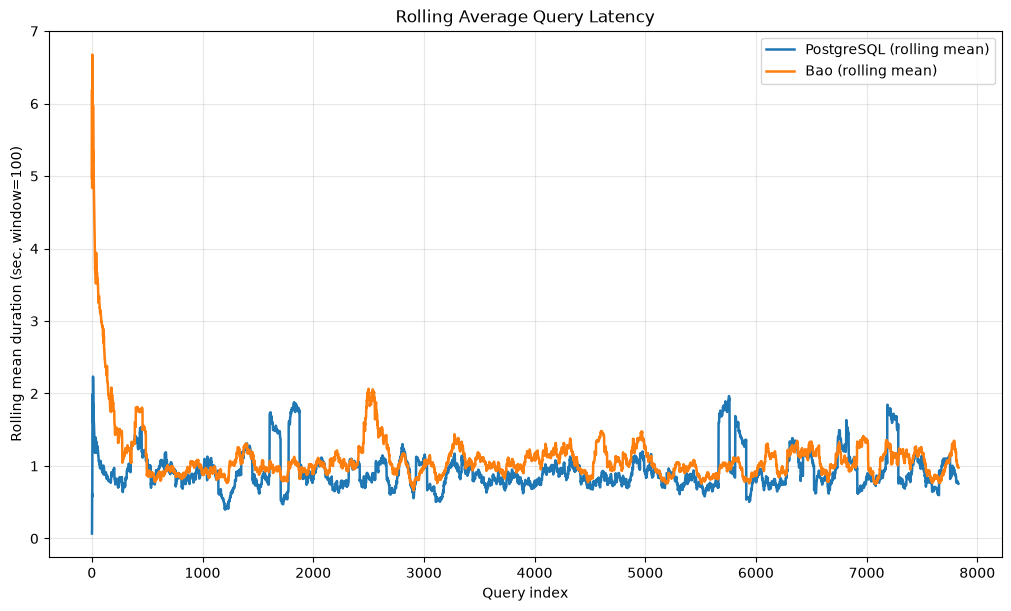

In [4]:
retrain_window = 100

# Duration-only cumulative curve. The CSVs have no start/end timestamps, so
# inter-query wall-clock gaps and retraining stalls cannot be reconstructed.
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
for frame, label, color in [(pg, "PostgreSQL", "tab:blue"), (bao, "Bao", "tab:orange")]:
    ax.step(frame["duration_sec"].cumsum() / 60, frame["cumulative_count"],
            where="post", label=label, color=color, linewidth=1.8)
ax.set_xlabel("Cumulative query time (minutes)")
ax.set_ylabel("Cumulative queries completed")
ax.set_title("Cumulative Queries Completed Using Query Durations Only")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(outdir / "01_duration_cumulative_curve.png", dpi=150)
plt.show()

# Rolling latency / learning curve.
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
for frame, label, color in [(pg, "PostgreSQL", "tab:blue"), (bao, "Bao", "tab:orange")]:
    rolling = frame["duration_sec"].rolling(retrain_window, min_periods=1).mean()
    ax.plot(frame["query_index"], rolling, label=f"{label} (rolling mean)",
            color=color, linewidth=1.8)
ax.set_xlabel("Query index")
ax.set_ylabel(f"Rolling mean duration (sec, window={retrain_window})")
ax.set_title("Rolling Average Query Latency")
ax.legend()
ax.grid(alpha=0.3)
fig.savefig(outdir / "02_rolling_latency.png", dpi=150)
plt.show()

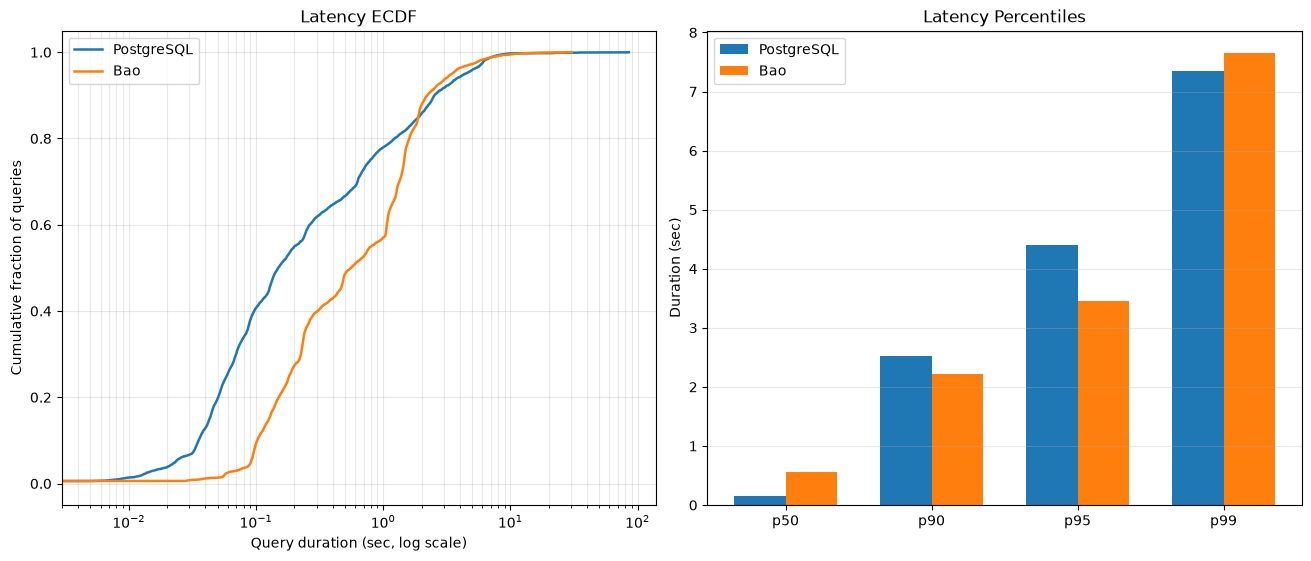

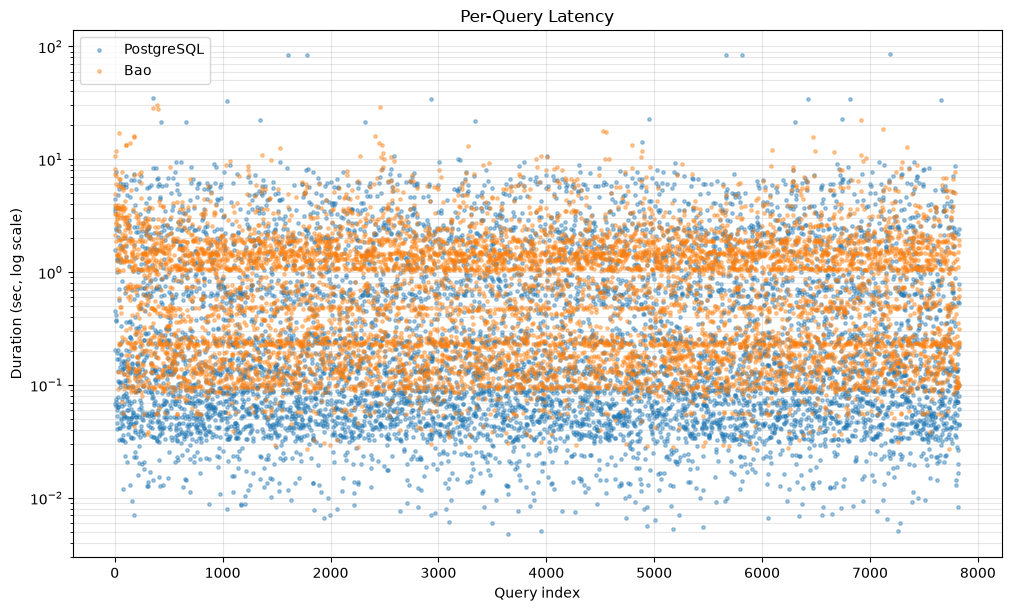

In [5]:
# Latency distribution: ECDF and percentile comparison.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
ax = axes[0]
for frame, label, color in [(pg, "PostgreSQL", "tab:blue"), (bao, "Bao", "tab:orange")]:
    values = np.sort(frame["duration_sec"].to_numpy())
    fraction = np.arange(1, len(values) + 1) / len(values)
    ax.plot(values, fraction, label=label, color=color, linewidth=1.8)
ax.set_xscale("log")
ax.set_xlabel("Query duration (sec, log scale)")
ax.set_ylabel("Cumulative fraction of queries")
ax.set_title("Latency ECDF")
ax.legend()
ax.grid(alpha=0.3, which="both")

ax = axes[1]
selected_percentiles = [50, 90, 95, 99]
pg_values = [pg["duration_sec"].quantile(p / 100) for p in selected_percentiles]
bao_values = [bao["duration_sec"].quantile(p / 100) for p in selected_percentiles]
x = np.arange(len(selected_percentiles))
width = 0.35
ax.bar(x - width / 2, pg_values, width, label="PostgreSQL", color="tab:blue")
ax.bar(x + width / 2, bao_values, width, label="Bao", color="tab:orange")
ax.set_xticks(x, [f"p{p}" for p in selected_percentiles])
ax.set_ylabel("Duration (sec)")
ax.set_title("Latency Percentiles")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.savefig(outdir / "03_latency_distribution.png", dpi=150)
plt.show()

# Raw per-query latency, preserving each run's order.
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.scatter(pg["query_index"], pg["duration_sec"], s=6, alpha=0.4,
           label="PostgreSQL", color="tab:blue")
ax.scatter(bao["query_index"], bao["duration_sec"], s=6, alpha=0.4,
           label="Bao", color="tab:orange")
ax.set_yscale("log")
ax.set_xlabel("Query index")
ax.set_ylabel("Duration (sec, log scale)")
ax.set_title("Per-Query Latency")
ax.legend()
ax.grid(alpha=0.3, which="both")
fig.savefig(outdir / "04_raw_scatter.png", dpi=150)
plt.show()

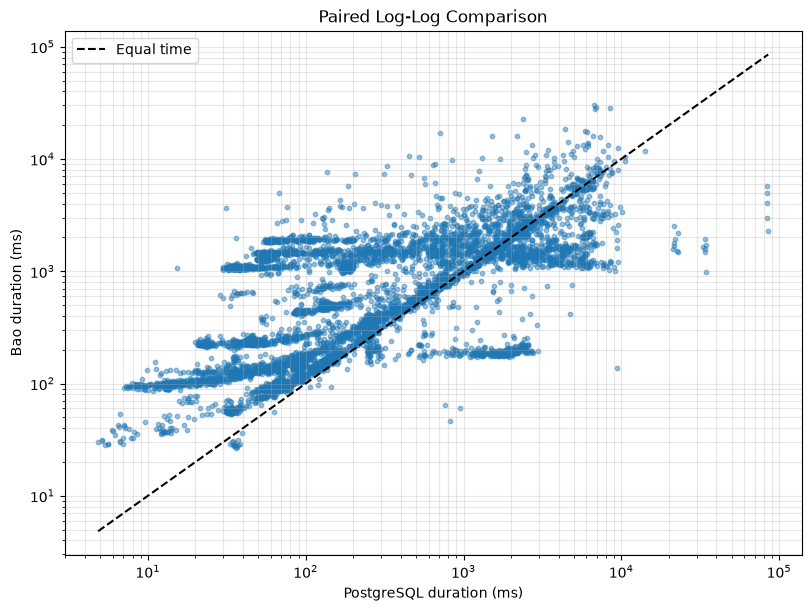

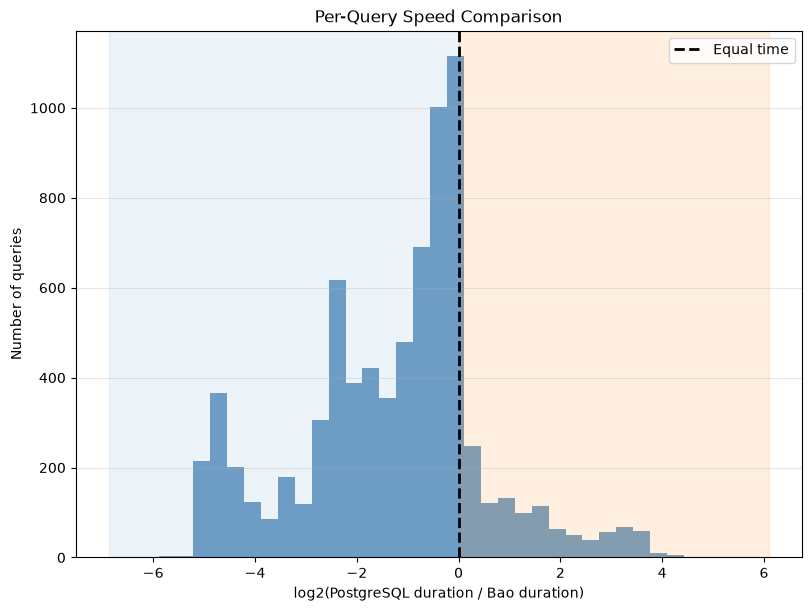

Plots written to: \\wsl.localhost\Ubuntu-22.04\home\mini\bao\mihini\BaoForPostgreSQL\bao_server\plots\bao_vs_pg_notebook


In [6]:
# Paired log-log scatter: points below y=x mean Bao is faster.
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
ax.scatter(positive["duration_ms_pg"], positive["duration_ms_bao"], s=10, alpha=0.45)
line_min = min(positive["duration_ms_pg"].min(), positive["duration_ms_bao"].min())
line_max = max(positive["duration_ms_pg"].max(), positive["duration_ms_bao"].max())
ax.plot([line_min, line_max], [line_min, line_max], "k--", label="Equal time")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("PostgreSQL duration (ms)")
ax.set_ylabel("Bao duration (ms)")
ax.set_title("Paired Log-Log Comparison")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.savefig(outdir / "05_paired_log_log_comparison.png", dpi=150)
plt.show()

# Speedup distribution: one value per matched query.
bins = np.linspace(positive["log2_speedup"].min(), positive["log2_speedup"].max(), 40)
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
ax.hist(positive["log2_speedup"], bins=bins, alpha=0.75, color="steelblue")
ax.axvline(0, color="black", linestyle="--", linewidth=2, label="Equal time")
ax.axvspan(positive["log2_speedup"].min(), 0, color="tab:blue", alpha=0.08)
ax.axvspan(0, positive["log2_speedup"].max(), color="tab:orange", alpha=0.12)
ax.set_xlabel("log2(PostgreSQL duration / Bao duration)")
ax.set_ylabel("Number of queries")
ax.set_title("Per-Query Speed Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.savefig(outdir / "06_speedup_distribution.png", dpi=150)
plt.show()

print(f"Plots written to: {outdir.resolve()}")